# Weekly receiver targets and PPR scoring
**Brendan Myers**

Which has the stronger association with next-week PPR scoring for a 2024 NFL wide receiver: this week’s targets or this week’s PPR points? Run the notebook from the project root.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display

assert Path("scripts/collect.py").exists(), "Open this notebook from the repository root."
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)

Python: 3.12.14
pandas: 2.2.3


## 1. Collect and preserve the source

The collector sends an identifying User-Agent, waits two seconds between requests (including redirects), stops on access/rate-limit errors, and saves the unmodified CSV plus collection metadata. It checks the saved SHA-256 checksum and uses the cached file on repeat runs. The saved output below uses the successful November 8 download.

In [2]:
result = subprocess.run([sys.executable, "scripts/collect.py"], capture_output=True, text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
result.check_returncode()
metadata = json.loads(Path("data/collection_metadata.json").read_text())
print(json.dumps(metadata, indent=2))

Using cached raw file: data/raw/player_stats_2024_2026-11-08.csv

{
  "source_url": "https://github.com/nflverse/nflverse-data/releases/download/player_stats/player_stats_2024.csv",
  "collected_at_utc": "2026-11-08T23:01:52.862113+00:00",
  "http_status": 200,
  "user_agent": "BrendanMyers-ClassResearch/1.0 (+https://github.com/brmy2261/nfl-wide-receiver-targets-and-ppr)",
  "pause_seconds": 2,
  "raw_path": "data/raw/player_stats_2024_2026-11-08.csv",
  "raw_records": 5597,
  "raw_bytes": 1674023,
  "raw_columns": 53,
  "sha256": "4f1598c9a6ba396a52e256762a0d9148abd22cdf856f26fc8825fa1d1dc49631",
  "robots_url": "https://github.com/robots.txt",
  "robots_http_status": 200,
  "license_url": "https://github.com/nflverse/nflverse-data/blob/main/LICENSE.md"
}


## 2. Clean and match consecutive weeks

The cleaning script filters 2024 regular-season WR records, keeps seven fields, checks missing/invalid values and duplicate player-week keys, and produces one row per player-week. It joins exactly week *t* to week *t+1*, never bridging an unobserved week and never assigning missing weeks zero points. The output includes all row counts and previews.

In [3]:
result = subprocess.run([sys.executable, "scripts/clean.py"], capture_output=True, text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
result.check_returncode()

{
  "source_collected_at_utc": "2026-11-08T23:01:52.862113+00:00",
  "source_sha256": "4f1598c9a6ba396a52e256762a0d9148abd22cdf856f26fc8825fa1d1dc49631",
  "raw_records": 5597,
  "raw_columns": 53,
  "wr_regular_season_records_before_cleaning": 2132,
  "excluded_other_positions_or_seasons": 3465,
  "invalid_or_missing_rows_removed": 0,
  "exact_duplicate_rows_removed": 0,
  "conflicting_player_week_duplicates": 0,
  "clean_weekly_records": 2132,
  "unique_receivers": 227,
  "week_min": 1,
  "week_max": 18,
  "predictor_rows_weeks_1_to_17": 2012,
  "consecutive_week_pairs": 1560,
  "eligible_rows_without_following_week": 452,
  "weekly_sample_records": 50,
  "pairs_sample_records": 50,
  "retained_fields": [
    "player_id",
    "season",
    "season_type",
    "week",
    "position",
    "targets",
    "fantasy_points_ppr"
  ],
  "sample_random_seed": 42
}

Clean weekly data preview:
 player_id  season season_type  week position  targets  fantasy_points_ppr
00-0030035    2024         R

## 3. Inspect the committed samples

Each sample has 50 rows selected with random seed 42, then sorted. These samples illustrate the schema; final analysis will use the full local paired table. See [the data dictionary](data/README.md) for every field and privacy/attribution notes.

In [4]:
weekly_sample = pd.read_csv("data/wr_weekly_sample.csv", dtype={"player_id": "string"})
pairs_sample = pd.read_csv("data/wr_pairs_sample.csv", dtype={"player_id": "string"})
print("Weekly sample:", weekly_sample.shape)
display(weekly_sample.head(10))
print("Paired sample:", pairs_sample.shape)
display(pairs_sample.head(10))
assert pairs_sample["next_week"].eq(pairs_sample["week"] + 1).all()
assert not weekly_sample.isna().any().any()
assert not pairs_sample.isna().any().any()
print("Sample checks passed: no missing values, and every outcome is exactly one week later.")

Weekly sample: (50, 7)
Paired sample: (50, 10)
Sample checks passed: no missing values, and every outcome is exactly one week later.


,player_id,season,season_type,week,position,targets,fantasy_points_ppr
0,00-0031236,2024,REG,18,WR,9,4.0
1,00-0031544,2024,REG,5,WR,10,10.0
2,00-0031544,2024,REG,7,WR,5,16.6
3,00-0032775,2024,REG,1,WR,7,8.2
4,00-0033375,2024,REG,14,WR,7,22.3
5,00-0033536,2024,REG,4,WR,5,10.7
6,00-0033536,2024,REG,15,WR,2,2.5
7,00-0033536,2024,REG,16,WR,3,5.4
8,00-0033555,2024,REG,6,WR,2,7.8
9,00-0033589,2024,REG,8,WR,5,7.9


,player_id,season,season_type,week,position,targets,fantasy_points_ppr,next_week_ppr,next_week,target_group
0,00-0030564,2024,REG,2,WR,2,1.9,19.3,3,0-3
1,00-0031381,2024,REG,8,WR,6,9.4,22.1,9,4-7
2,00-0031381,2024,REG,16,WR,13,19.8,9.7,17,8+
3,00-0032211,2024,REG,15,WR,1,3.2,3.9,16,0-3
4,00-0032464,2024,REG,11,WR,2,5.0,0.0,12,0-3
5,00-0033009,2024,REG,8,WR,6,4.4,0.3,9,4-7
6,00-0033040,2024,REG,9,WR,5,12.0,11.7,10,4-7
7,00-0033536,2024,REG,9,WR,2,1.6,10.2,10,0-3
8,00-0033555,2024,REG,17,WR,2,5.3,5.5,18,0-3
9,00-0033589,2024,REG,14,WR,5,4.5,3.9,15,4-7


## Collection and cleaning results

Of the 2,012 eligible predictor records, 452 lacked a record the following week. A bye or another absence can create this gap. The comparisons below use the remaining consecutive-week pairs.

## 4. Compare targets and current points

Each row contributes one receiver and two consecutive NFL weeks. Both Pearson correlations use exactly the same rows and next-week outcome.

In [5]:
pairs = pd.read_csv('data/processed/wr_consecutive_weeks_2024.csv', dtype={'player_id': 'string'})
predictors = ['targets', 'fantasy_points_ppr']
outcome = 'next_week_ppr'
assert not pairs[predictors + [outcome]].isna().any().any()
assert pairs['next_week'].eq(pairs['week'] + 1).all()
r = pairs[predictors].corrwith(pairs[outcome])
print(f'{len(pairs):,} consecutive-week pairs')
print(r.round(4).to_string())
print(f"Difference (targets minus current PPR): {r['targets'] - r['fantasy_points_ppr']:+.4f}")

1,560 consecutive-week pairs
targets               0.4095
fantasy_points_ppr    0.3570
Difference (targets minus current PPR): +0.0525


In [6]:
groups = (pairs.groupby('target_group')[outcome].agg(pairs='size', mean_next_week_ppr='mean')
          .reindex(['0-3', '4-7', '8+']))
assert groups['pairs'].sum() == len(pairs)
display(groups.round(2))

,pairs,mean_next_week_ppr
target_group,,
0-3,587,5.91
4-7,600,10.13
8+,373,13.94


## 5. Inspect the spread in next-week scoring

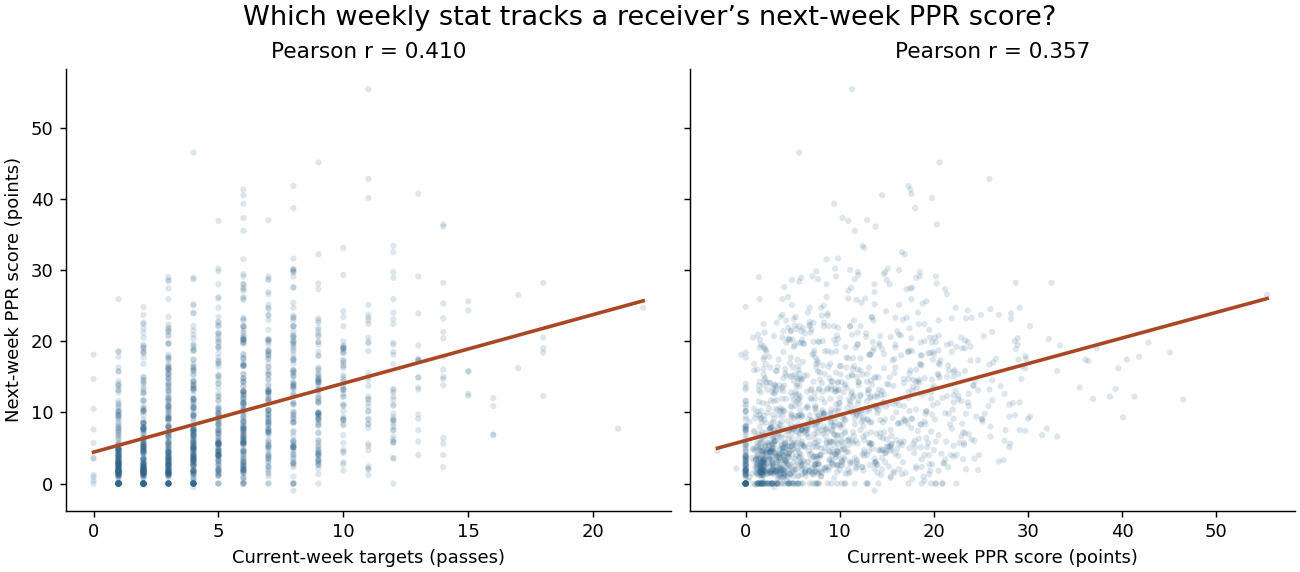

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, constrained_layout=True)
fig.suptitle('Which weekly stat tracks a receiver’s next-week PPR score?', fontsize=15)
for ax, field, label in zip(axes, predictors, ['Current-week targets (passes)', 'Current-week PPR score (points)']):
    x, y = pairs[field], pairs[outcome]
    ax.scatter(x, y, s=12, alpha=0.16, color='#31658a', edgecolors='none')
    limits = np.array([x.min(), x.max()])
    slope, intercept = np.polyfit(x, y, 1)
    ax.plot(limits, slope * limits + intercept, color='#aa4825', linewidth=2)
    ax.set(xlabel=label, title=f'Pearson r = {r[field]:.3f}')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Next-week PPR score (points)')
folder = Path('figures')
folder.mkdir(exist_ok=True)
chart = folder / 'next-week-ppr.png'
fig.savefig(chart, dpi=130)
plt.close(fig)
display(Image(filename=str(chart)))

*Figure 1. Across 1,560 consecutive-week pairs, targets had a stronger correlation with next-week PPR points than current PPR points did, although scores varied widely around both fitted lines.*

## Preliminary findings

Targets had the stronger association with next-week PPR scoring in the 2024 regular season. Across **1,560 consecutive-week pairs**, the Pearson correlation was **0.410** for current targets and **0.357** for current PPR points, a difference of **+0.053** using unrounded values. Receivers who drew eight or more targets averaged **13.94 PPR points** the following week, compared with **5.91** after three or fewer targets. These pooled comparisons include repeated observations of receivers. They can reflect differences between players as well as changes in a player’s workload. The results apply to receivers observed in consecutive weeks and describe one season.